Logistic Regression
=

In [2]:
import sys

In [3]:
print(sys.executable)

/home/simonque/Documents/code/env/bin/python3


In [4]:
print(sys.prefix)

/home/simonque/Documents/code/env


In [5]:
debug = 0
def printd(s: str, debug:int):
    if debug: 
        print(s)

# Import Libraries

In [119]:
import numpy as np 
import matplotlib.pyplot as plt
import struct
import argparse


# Univariate Gaussian Data Generator

In [120]:
'''
@brief Generate Gaussian distributed samples using the Marsaglia polar method 

@param m mean
@param s variance

@return a number from a Gaussian distribution N(m,s)
'''
def generate_gaussian_data(m: float, s: float):
    z = 0
    # if s is within the unit circle, proceed.
    # elif s is outside the unit circle, get another set of random numbers.
    while z == 0 or z >= 1.0:
        # generate two random numbers [-1,1]
        u1 = np.random.uniform(-1.0, 1.0)
        u2 = np.random.uniform(-1.0, 1.0)
    
        # get the polar magnitude 
        z = u1 ** 2 + u2 ** 2

    # compute the polar transform multiplier 
    multiplier = np.sqrt(-2.0 * np.log(z) / z)

    # generate a Gaussian distributed sample 
    sample = m + u1 * multiplier * np.sqrt(s)
    
    return sample
    

# Generate data

In [121]:
def generate_2d_data_with_label(n: int,
                  mx: float,
                 vx: float,
                 my: float,
                 vy: float,
                label: int):
    X = []
    for i in range(n):
        X.append((generate_gaussian_data(mx, vx),
                      generate_gaussian_data(my, vy)))
    y = [label] * n
    return X, y

def generate_multi_label_points(points_distribution: list[tuple[tuple[int]]],
                                labels: list[int]):
    X_total = []
    y_total = []
    assert(len(points_distribution) == len(labels))
    for i in range(len(labels)):
        X, y = generate_2d_data_with_label(n,
                                           points_distribution[i][0][0], 
                                           points_distribution[i][0][1], 
                                           points_distribution[i][1][0],
                                           points_distribution[i][1][1],
                                           labels[i])
        print(len(X), len(y))
        X_total += X
        y_total += y
    print(len(X_total), len(y_total))
    X_arr = np.array(X_total)
    y_arr = np.array(y_total)
    return X_arr, y_arr

# n = 50
# mx1, vx1, my1, vy1 = 1, 2, 1, 2
# mx2, vx2, my2, vy2 = 10, 2, 10, 2

# points_distributions = [((mx1, vx1), (my1, vy1)),
#                        ((mx2, vx2), (my2, vy2))]
# labels = [0,1]
# X_arr, y_arr = generate_multi_label_points(points_distributions, labels)

# Sigmoid function

In [122]:
def sigmoid(z: float):
    return 1.0 / (1.0 + np.exp(-z))

# Logistic Regression

## Steepest Descent

In [123]:
def gradient_descent(X, 
                     y, 
                     learning_rate = 0.01, 
                     max_iter = 10000, 
                     tolerance = 1e-6):
    # initialize weights 
    w = np.zeros(X.shape[1] + 1)
    prev_w = w
    print(f"w.shape = {w.shape}")
    # iteratively move in the direction of the gradient  
    i = 0
    for i in range(max_iter):
        # create the design matrix.
        '''
        with 2D points as X, the design matrix has a constant 
        column of ones concatenated to the left as the bias 
        term, so the resulting design matrix is of the shape
        N x 3.
        '''
        X_design = np.hstack([np.ones((X.shape[0],1)), X])
        # print(f"X_design.shape = {X_design.shape}")

        # multiply design matrix with weights 
        z = X_design @ w
        # print(f"z.shape = {z.shape}")

        # get the predictions by applying the sigmoid function
        # to z
        p = sigmoid(z)
        
        # get the gradient of the loss function (binary cross-entropy
        # negative log-likelihood)
        grad = X_design.T @ (p - y)
        # print(f"grad.shape = {grad.shape}")

        # update the weights with the gradient and learning rate 
        prev_w = w
        w = w - learning_rate * grad

        # stop iteration when the norm (distance) between weights 
        # converge
        i+=1
        if np.linalg.norm(w - prev_w) < tolerance:
            break;
    print(f"num_iterations = {i}")
    return w
        
# w_gradient_descent = gradient_descent(X_arr, y_arr)
# w_gradient_descent

## Newton's Method

In [124]:
def newtons_method(X, 
                   y, 
                   max_iter = 10000, 
                   tolerance=1e-6):
    # learning rate for gradient descent fallback 
    learning_rate = 1e-2
    
    # initialize weights 
    w = np.zeros(X.shape[1] + 1)
    prev_w = w
    print(f"w.shape = {w.shape}")
    # iterate using Newton's method
    # 
    i = 0
    for i in range(2):
        # create the design matrix.
        '''
        with 2D points as X, the design matrix has a constant 
        column of ones concatenated to the left as the bias 
        term, so the resulting design matrix is of the shape
        N x 3.
        '''
        X_design = np.hstack([np.ones((X.shape[0],1)), X])
        print(f"X_design.shape = {X_design.shape}")

        # multiply design matrix with weights 
        z = X_design @ w
        # print(f"z.shape = {z.shape}")

        # get the predictions by applying the sigmoid function
        # to z
        p = sigmoid(z)
        
        # get the gradient of the loss function (binary cross-entropy
        # negative log-likelihood)
        grad = X_design.T @ (p - y)
        # print(f"grad.shape = {grad.shape}")

        # first form the weight matrix with the derivative of each prediction
        # y_hat wrt. w.
        # Mathematically, S is a diagonal matrix, but to reduce memory
        # usage, rows in X_design are scaled by S before multiplying the 
        # product with X_design.T.
        S = p * (1 - p)
        S = np.expand_dims(S, axis=-1)
        print(f"S.shape = {S.shape}")
        # get the Hessian (2nd order derivative) of the loss function.
        # Expected shape of Hessian is d x d
        # (d x N) @ ((N x d) * (N x 1))
        hessian = (X_design.T) @ (X_design * S)
        print(f"hessian.shape = {hessian.shape}")

        # update previous weights
        prev_w = w
        # check if the Hessian is singular
        # 
        det = np.linalg.det(hessian)
        print(f"det = {det}")
        # if determinant is zero, hessian matrix determinant is zero,
        # so fallback to gradient descent.
        if abs(det) < 1e-10:
            print(f"hessian matrix determinant is singular.")
            w = w - learning_rate * grad
        # else,  
        else:
            w = w - np.linalg.solve(hessian, grad)

        # stop iteration when the norm (distance) between weights 
        # converge
        i+=1
        if np.linalg.norm(w - prev_w) < tolerance:
            break;
    print(f"num_iterations = {i}")
    return w
            

# w_newtons_method = newtons_method(X_arr, y_arr)
# w_newtons_method

## Predict results

In [127]:
def predict(w:np.array, 
            X: np.array):
    print(f"w.shape = {w.shape}")
    print(f"X.shape = {X.shape}")

    # create design matrix
    X_design = np.hstack([np.ones((X.shape[0],1)), X])
    print(f"X_design.shape = {X_design.shape}")

    # multiply design matrix with weights 
    z = X_design @ w
    print(f"z.shape = {z.shape}")

    # get the sigmoid of the product 
    p = sigmoid(z)
    print(f"p.shape = {p.shape}")
    print(f"p = {p}")

    # create predictions from sigmoid
    predictions = (p >= 0.5).astype(int)
    print(f"predictions = \n{predictions}")
    return predictions
    
# y_preds = predict(w_gradient_descent, X_arr)

# plot results

In [128]:
def plot_results(
    points,
    y_ground_truth,
    y_gradient_descent,
    y_newtons_method,
    filename: str = "logistic_regression.png"):

    fig, axes = plt.subplots(nrows=1,
                        ncols=3,
                        squeeze = False,
                        sharex=False,
                        sharey = True,
                        figsize = (18,6))

    ax = axes[0,0]
    ax.scatter(points[y_ground_truth == True ,0], points[y_ground_truth == True ,1], color = "blue")
    ax.scatter(points[y_ground_truth == False ,0], points[y_ground_truth == False ,1],color = "red")
    ax.set_title("Ground truth")
    
    ax = axes[0,1]
    ax.scatter(points[y_gradient_descent == True ,0], points[y_gradient_descent == True ,1], color = "blue")
    ax.scatter(points[y_gradient_descent == False ,0], points[y_gradient_descent == False ,1],color = "red")
    ax.set_title("Gradient descent")
    
    ax = axes[0,2]
    ax.scatter(points[y_newtons_method == True ,0], points[y_newtons_method == True ,1], color = "blue")
    ax.scatter(points[y_newtons_method == False ,0], points[y_newtons_method == False ,1],color = "red")
    ax.set_title("Newton's method")
    
    plt.tight_layout()
    plt.savefig(filename)
    plt.show()

# plot_results(X_arr, y_arr, y_preds, None)

# print confusion matrix

In [130]:
def print_metrics(y_pred: np.array,
                y_ground: np.array,
                title: str = "title",
                 class_name=""):
    print(f"{title}")
    print("----------------------------------------------------------------------")
    tp = np.sum((y_pred == 1) & (y_ground == 1))
    tn = np.sum((y_pred == 0) & (y_ground == 0))
    fp = np.sum((y_pred == 1) & (y_ground == 0))
    fn = np.sum((y_pred == 0) & (y_ground == 1))
    
    # print confusion matrix
    print(f"Confusion Matrix {class_name}:\n")
    print(f"\t\tPredict 0\tPredict 1")
    print(f"Real 0\t\t{tn}\t\t{fp}")
    print(f"Real 1\t\t{fn}\t\t{tp}")
    
    # print sensitivity and specificity
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    print(f"Sensitivity (successfully predict cluster 1): {sensitivity}")
    print(f"Specificity (successfully predict cluster 2): {specificity}")
    
# print_metrics(y_preds, y_arr)

# Test run 

50 50
50 50
100 100
w.shape = (3,)
num_iterations = 10000
w.shape = (3,)
X_design.shape = (100, 3)
S.shape = (100, 1)
hessian.shape = (3, 3)
det = 1142773.4168136548
X_design.shape = (100, 3)
S.shape = (100, 1)
hessian.shape = (3, 3)
det = 101358.46296950673
num_iterations = 2
w.shape = (3,)
X.shape = (100, 2)
X_design.shape = (100, 3)
z.shape = (100,)
p.shape = (100,)
p = [1.70231563e-03 1.18280778e-04 2.75178887e-04 1.54146622e-05
 3.73955618e-03 3.61772244e-04 3.56687530e-06 3.56754384e-04
 3.20517492e-06 5.10320149e-05 2.83606436e-06 2.62342568e-05
 7.44509087e-06 2.70332305e-03 5.63223074e-06 1.50340184e-03
 6.90478349e-04 2.46737027e-04 3.10567176e-04 1.77098655e-05
 2.54189810e-05 1.10905099e-05 3.81012998e-04 6.26882876e-03
 6.81711613e-05 5.68513330e-05 3.83361700e-05 3.51125912e-07
 8.49072089e-06 1.00590344e-04 7.05331831e-05 2.25389310e-03
 1.07033178e-05 4.88341115e-04 5.45357881e-04 7.12167547e-04
 1.73709172e-05 4.60619798e-03 2.00388751e-04 1.19451628e-05
 4.14887893e-0

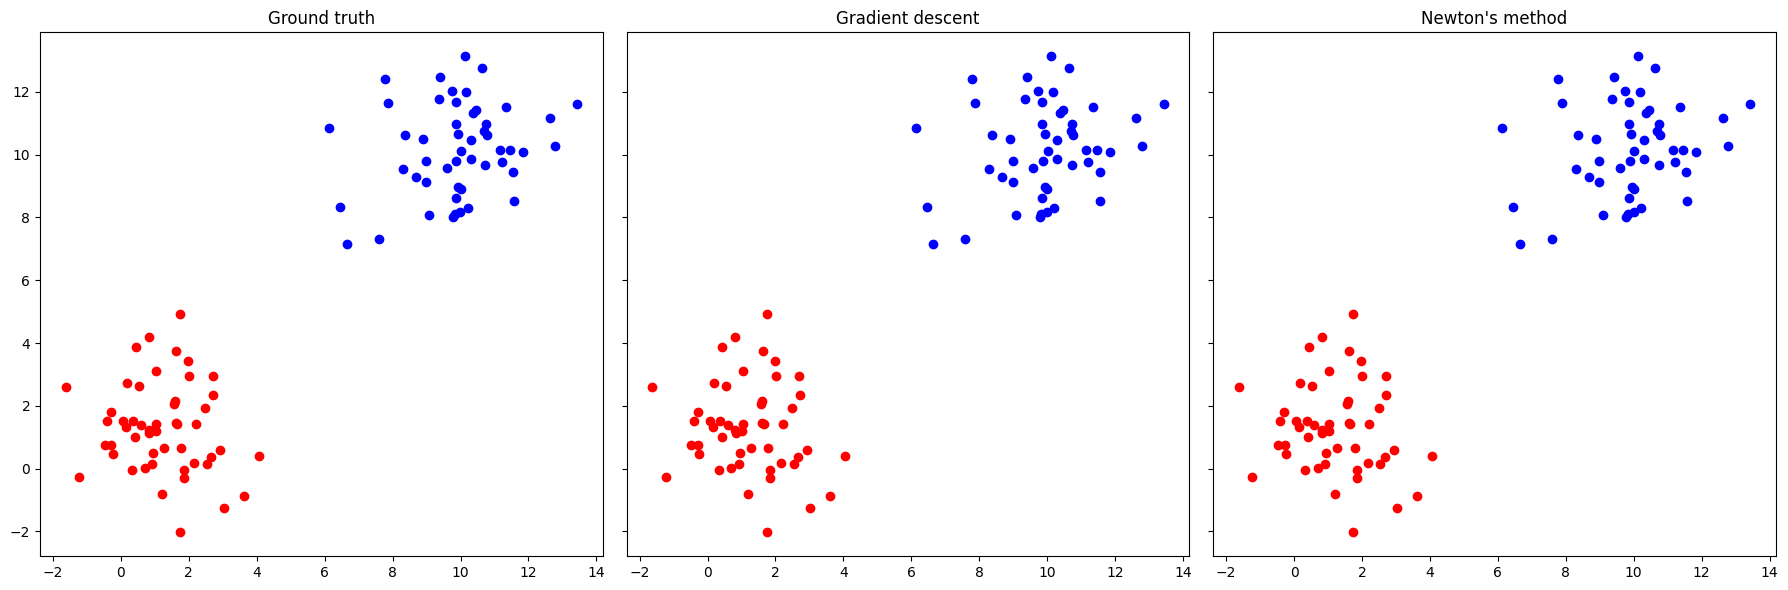

In [131]:
n = 50
mx1, vx1, my1, vy1 = 1, 2, 1, 2
mx2, vx2, my2, vy2 = 10, 2, 10, 2

points_distributions = [((mx1, vx1), (my1, vy1)),
                       ((mx2, vx2), (my2, vy2))]
labels = [0,1]
X_arr, y_arr = generate_multi_label_points(points_distributions, labels)
w_gradient_descent = gradient_descent(X_arr, y_arr)
w_newtons_method = newtons_method(X_arr, y_arr)
y_gradient_descent = predict(w_gradient_descent, X_arr)
y_newtons_method = predict(w_newtons_method, X_arr)
print_metrics(y_gradient_descent, y_arr, "Gradient descent logistic regression results")
print_metrics(y_newtons_method, y_arr, "Newton's Method logistic regression results")
plot_results(X_arr, y_arr, y_gradient_descent, y_newtons_method)


50 50
50 50
100 100
w.shape = (3,)
num_iterations = 582
w.shape = (3,)
X_design.shape = (100, 3)
S.shape = (100, 1)
hessian.shape = (3, 3)
det = 222323.47070288294
X_design.shape = (100, 3)
S.shape = (100, 1)
hessian.shape = (3, 3)
det = 48854.377418346616
num_iterations = 2
w.shape = (3,)
X.shape = (100, 2)
X_design.shape = (100, 3)
z.shape = (100,)
p.shape = (100,)
p = [0.04697405 0.57323109 0.13778692 0.09819138 0.4830431  0.08687556
 0.25923288 0.4556983  0.04372844 0.44862224 0.73493807 0.01675552
 0.00591574 0.01252583 0.02205376 0.02319559 0.1376632  0.05301292
 0.09556556 0.13348992 0.41108803 0.73565086 0.20552628 0.0928674
 0.24794297 0.1726981  0.29958051 0.58279792 0.11485026 0.07116231
 0.26008247 0.03576371 0.01083546 0.37099001 0.22372268 0.43439636
 0.99032954 0.39489596 0.79044921 0.17529869 0.10759826 0.04858245
 0.04992051 0.03089961 0.61405127 0.0386682  0.03122082 0.22444814
 0.49969134 0.14924079 0.99992459 0.93920812 0.48948328 0.9659127
 0.46458631 0.46803467 0.

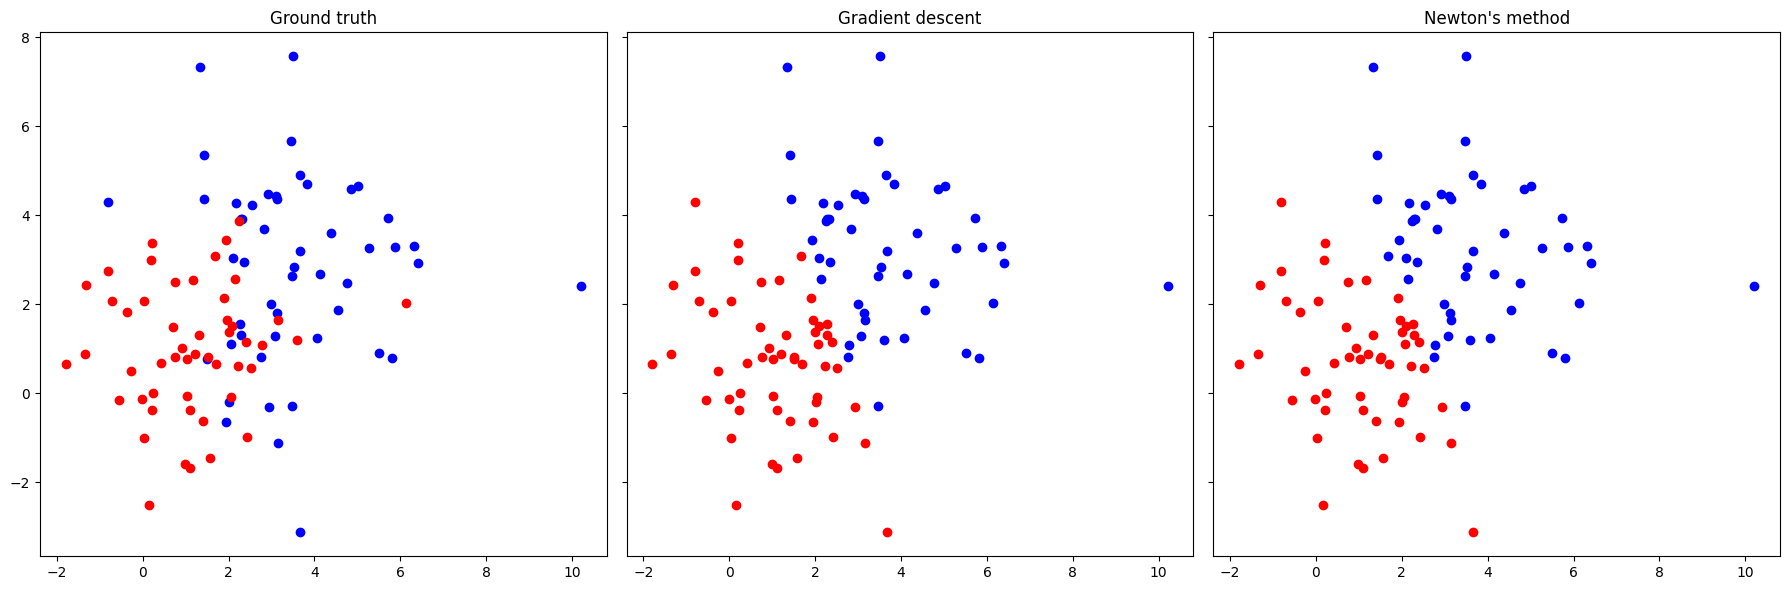

In [132]:
n = 50
mx1, vx1, my1, vy1 = 1, 2, 1, 2
mx2, vx2, my2, vy2 = 3, 4, 3, 4

points_distributions = [((mx1, vx1), (my1, vy1)),
                       ((mx2, vx2), (my2, vy2))]
labels = [0,1]
X_arr, y_arr = generate_multi_label_points(points_distributions, labels)
w_gradient_descent = gradient_descent(X_arr, y_arr)
w_newtons_method = newtons_method(X_arr, y_arr)
y_gradient_descent = predict(w_gradient_descent, X_arr)
y_newtons_method = predict(w_newtons_method, X_arr)
print_metrics(y_gradient_descent, y_arr, "Gradient descent logistic regression results")
print_metrics(y_newtons_method, y_arr, "Newton's Method logistic regression results")
plot_results(X_arr, y_arr, y_gradient_descent, y_newtons_method)